In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import os

file_path = os.path.join(
    os.path.expanduser("~"),
    "Documents",
    "Churn_Modelling.csv"
)

print(file_path)
print(os.path.exists(file_path))

C:\Users\ACER\Documents\Churn_Modelling.csv
True


In [3]:
df = pd.read_csv(file_path)

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.shape

(10000, 14)

In [5]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [7]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df = df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname']
)

df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [11]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [12]:
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

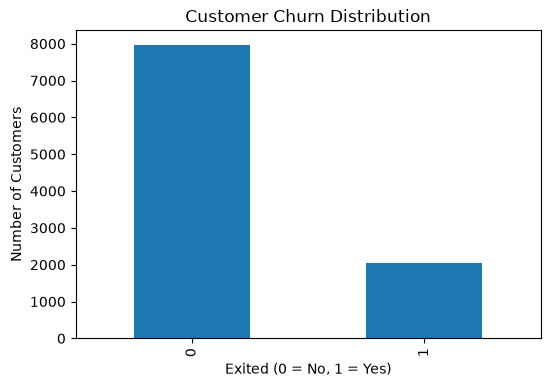

In [13]:
df['Exited'].value_counts().plot(
    kind='bar',
    figsize=(6, 4)
)

plt.title('Customer Churn Distribution')
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()

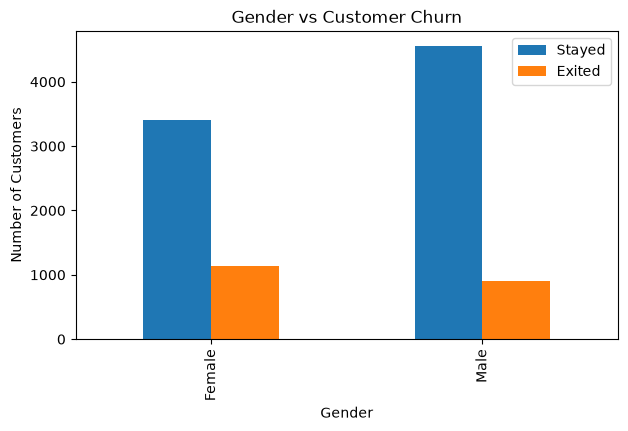

In [14]:
pd.crosstab(
    df['Gender'],
    df['Exited']
).plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Gender vs Customer Churn')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.legend(['Stayed', 'Exited'])
plt.show()

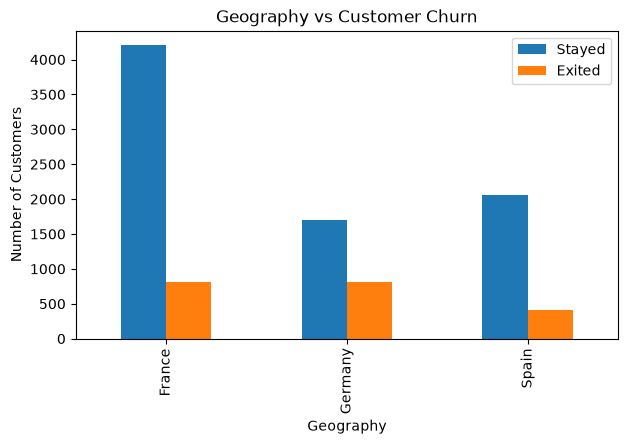

In [15]:
pd.crosstab(
    df['Geography'],
    df['Exited']
).plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Geography vs Customer Churn')
plt.xlabel('Geography')
plt.ylabel('Number of Customers')
plt.legend(['Stayed', 'Exited'])
plt.show()

In [16]:
df.groupby('Exited')['Age'].mean()

Exited
0    37.408389
1    44.837997
Name: Age, dtype: float64

In [17]:
df.groupby('Exited')['Balance'].mean()

Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64

In [18]:
pd.crosstab(
    df['IsActiveMember'],
    df['Exited'],
    normalize='index'
) * 100

Exited,0,1
IsActiveMember,,
0,73.149103,26.850897
1,85.730926,14.269074


In [19]:
df.select_dtypes(include='object').columns

C:\Users\ACER\AppData\Local\Temp\ipykernel_21464\3732952691.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['Geography', 'Gender'], dtype='str')

In [20]:
df['Gender'] = df['Gender'].map({
    'Female': 0,
    'Male': 1
})

df['Gender'].value_counts()

Gender
1    5457
0    4543
Name: count, dtype: int64

In [21]:
df = pd.get_dummies(
    df,
    columns=['Geography'],
    drop_first=True,
    dtype=int
)

df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,1


In [22]:
X = df.drop('Exited', axis=1)

X.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,1


In [23]:
y = df['Exited']

y.head()

0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 11)
Testing Data: (2000, 11)


In [25]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

print("Logistic Regression Model Created")

Logistic Regression Model Created


In [26]:
model.fit(X_train, y_train)

print("Model Training Completed")

Model Training Completed


C:\Users\ACER\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [27]:
y_pred = model.predict(X_test)

print(y_pred[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]


In [28]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 80.9 %


In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.60      0.18      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



In [30]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1543   50]
 [ 332   75]]


In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

print("Libraries Imported Successfully")

Libraries Imported Successfully


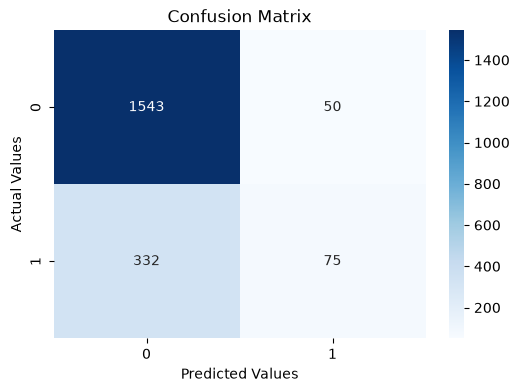

In [32]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

In [33]:
print("True Negative:", cm[0][0])
print("False Positive:", cm[0][1])
print("False Negative:", cm[1][0])
print("True Positive:", cm[1][1])

True Negative: 1543
False Positive: 50
False Negative: 332
True Positive: 75


In [34]:
y_prob = model.predict_proba(X_test)[:, 1]

print(y_prob[:10])

[0.12501682 0.3650469  0.15497973 0.16281474 0.1117188  0.20987802
 0.09303131 0.34281741 0.4179638  0.19820052]


In [35]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

print("AUC Score:", auc_score)

AUC Score: 0.7561120442476374


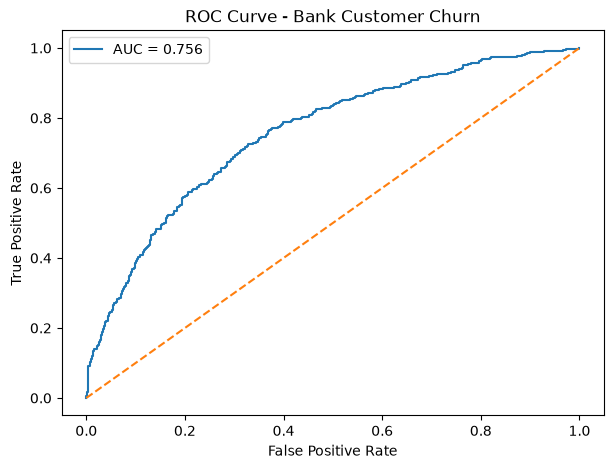

In [36]:
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'AUC = {auc_score:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.title('ROC Curve - Bank Customer Churn')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [37]:
customer = X_test.iloc[[0]]

customer

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
5702,585,1,36,7,0.0,2,1,0,94283.09,0,0


In [38]:
prediction = model.predict(customer)

if prediction[0] == 1:
    print("Customer May Leave the Bank")
else:
    print("Customer May Stay with the Bank")

Customer May Stay with the Bank


In [39]:
probability = model.predict_proba(customer)[0][1]

print("Churn Probability:", round(probability * 100, 2), "%")

Churn Probability: 12.5 %


In [40]:
total_customers = len(df)

churned_customers = df['Exited'].sum()

churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 10000
Churned Customers: 2037
Churn Rate: 20.37 %


In [41]:
geography_churn = df.groupby(
    'Exited'
).size()

print(geography_churn)

Exited
0    7963
1    2037
dtype: int64


In [42]:
geo_churn = pd.crosstab(
    df['Geography_Germany'],
    df['Exited']
)

print(geo_churn)

Exited                0     1
Geography_Germany            
0                  6268  1223
1                  1695   814


In [43]:
print("BANK CUSTOMER CHURN ANALYSIS")
print("----------------------------")

print("Total Customers:", len(df))

print("Churned Customers:",
      df['Exited'].sum())

print("Average Customer Age:",
      round(df['Age'].mean(), 2))

print("Average Balance:",
      round(df['Balance'].mean(), 2))

print("Model Accuracy:",
      round(accuracy * 100, 2), "%")

print("AUC Score:",
      round(auc_score, 3))

BANK CUSTOMER CHURN ANALYSIS
----------------------------
Total Customers: 10000
Churned Customers: 2037
Average Customer Age: 38.92
Average Balance: 76485.89
Model Accuracy: 80.9 %
AUC Score: 0.756
